In [35]:
import xarray as xr
import glob as glob
import xwrf

In [88]:
wrfiles = glob.glob('/home/nmathewa/Build_WRF/WRF-4.6.0-ARW/run/wrfout_d01*')


dset = xr.open_mfdataset(wrfiles,combine='nested',concat_dim='Time')

In [89]:
import numpy as np
ph = dset["PH"]  # perturbation geopotential
phb = dset["PHB"]  # base-state geopotential
geopotential = (ph + phb) 

height = (geopotential/9.81).mean(dim=['Time','south_north','west_east']).values[1:]


time_data = np.unique(dset.XTIME.values)
lon_data = np.unique(dset.XLONG.values)
lat_data = np.unique(dset.XLAT.values)
data_var = dset['T2'].values     

dset_new = xr.Dataset(
    {
        "T": (["time" , "lat", "lon"], data_var),
    },
    coords={
        "time": time_data,
        "lat": lat_data,
        "lon": lon_data,
    },
)

dset_new['T'] = dset_new['T'] - 273.15



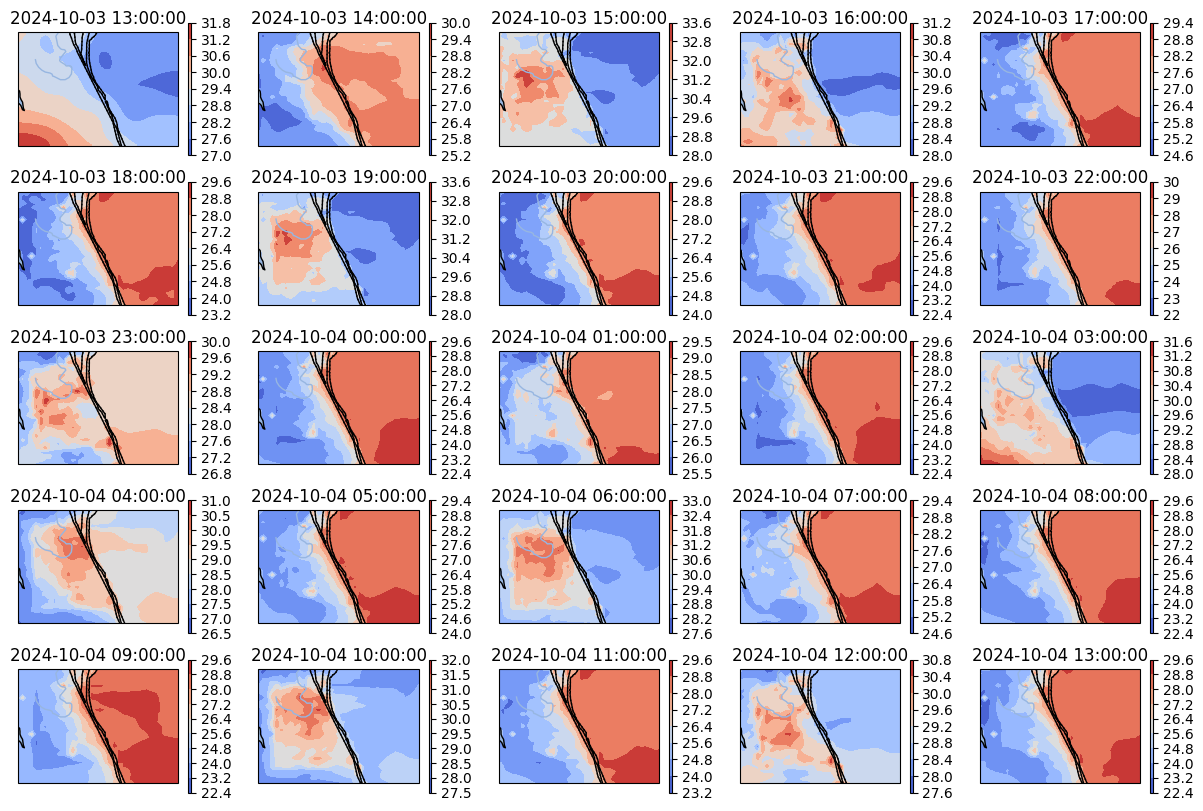

In [91]:


#draw labels 

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd

def plot_map(ax, data, lat, lon):
    ax.set_extent([lon.min(), lon.max(), lat.min(), lat.max()], crs=ccrs.PlateCarree())
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.add_feature(cfeature.STATES, linestyle=':')
    ax.add_feature(cfeature.LAND, edgecolor='black')
    ax.add_feature(cfeature.OCEAN)
    ax.add_feature(cfeature.LAKES, edgecolor='black')
    ax.add_feature(cfeature.RIVERS)
    
    cf = ax.contourf(lon, lat, data, transform=ccrs.PlateCarree(), cmap='coolwarm')
    time = data.time.values
    # utc to local time
    time = pd.to_datetime(time) - pd.Timedelta(hours=5)
    ax.set_title(time)
    plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.05, aspect=50)
    
    return ax


# facet plot

fig, axs = plt.subplots(5, 5, subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(15, 10))

for i, ax in enumerate(axs.flat):
    plot_map(ax, dset_new['T'].isel(time=i), lat_data, lon_data)



In [99]:
pip install plotly

  Using cached tenacity-9.0.0-py3-none-any.whl.metadata (1.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 92.6 MB/s eta 0:00:00:00:01
Using cached tenacity-9.0.0-py3-none-any.whl (28 kB)
Note: you may need to restart the kernel to use updated packages.


In [104]:
# create a slider plot with plotly

import plotly.graph_objects as go
import numpy as np

# Assuming dset_new['T'].values is a 3D array with shape (time, x, y)
# and dset_new['T'].time.values is a 1D array with time values

# Create figure
fig = go.Figure()

# Add initial frame
fig.add_trace(go.Heatmap(z=dset_new['T'].values[0], colorscale='jet'))

# Add frames
frames = [go.Frame(data=[go.Heatmap(z=dset_new['T'].values[k])],
                   name=str(dset_new['T'].time.values[k])) for k in range(len(dset_new['T'].time.values))]

fig.frames = frames

# Add slider
sliders = [dict(
    steps=[dict(method='animate',
                args=[[str(dset_new['T'].time.values[k])],
                      dict(mode='immediate',
                           frame=dict(duration=300, redraw=True),
                           transition=dict(duration=0))],
                label=str(dset_new['T'].time.values[k])) for k in range(len(dset_new['T'].time.values))],
    transition=dict(duration=0),
    x=0.1,
    xanchor='left',
    y=0,
    yanchor='top'
)]

fig.update_layout(
    title='Temperature (°C) at 2m',
    title_x=0.5,
    sliders=sliders
)

fig.show()

In [ ]:
from metpy.units import units
from metpy.interpolate import log_interpolate_1d

pressure = dset['P'] * units.Pa
hgt = dset['HGT'] * units.m
t = dset['T'] * units.K
plevs = [1000, 925, 850, 700, 500, 400, 300, 250, 200, 150, 100] * units.hPa






Note: you may need to restart the kernel to use updated packages.


In [31]:
height = (dset['PH'] + dset['PHB'])/9.81


height.isel(Time=0)



<xarray.DataArray (bottom_top_stag: 45, south_north: 111, west_east: 66)> Size: 1MB
dask.array<getitem, shape=(45, 111, 66), dtype=float32, chunksize=(45, 56, 33), chunktype=numpy.ndarray>
Coordinates:
    XLAT     (south_north, west_east) float32 29kB dask.array<chunksize=(56, 33), meta=np.ndarray>
    XLONG    (south_north, west_east) float32 29kB dask.array<chunksize=(56, 33), meta=np.ndarray>
    XTIME    datetime64[ns] 8B dask.array<chunksize=(), meta=np.ndarray>
Dimensions without coordinates: bottom_top_stag, south_north, west_east

In [7]:


var = 'T'

dset_new = xr.DataArray(data=data_var,
                        coords={'Time':time_data,
                                'lon':lon_data,
                                'lat':lat_data},
                        dims=['Time','lat','lon'])

ValueError: different number of dimensions on data and dims: 4 vs 3